# Importing Necessities

In [2]:
import os, random, math
import numpy as np
from PIL import Image
import copy

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
import torchvision
from torchvision.transforms import InterpolationMode

from pycocotools.coco import COCO
import pycocotools.mask as maskUtils

import matplotlib.pyplot as plt

import gradio as gr

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [4]:
dataset_dir = 'dataset'

# Importing Dataset

In [4]:
class CrosswalkShadowCocoDataset(Dataset):

    def __init__(self, dataset_dir, image_ids, train=True):

        self.dataset_dir = dataset_dir
        self.ann_file = os.path.join(dataset_dir, "_annotations.coco.json")
        self.coco = COCO(self.ann_file)
        self.image_ids = image_ids
        self.train = train

        cats = self.coco.loadCats(self.coco.getCatIds())


        self.coco_id_to_class = {}
        for cat in cats:
            name = cat["name"].lower()
            if "crosswalk" in name:

                self.coco_id_to_class[cat["id"]] = 1
            elif "shadow" in name:
                self.coco_id_to_class[cat["id"]] = 2

        self.mean = [0.485, 0.456, 0.406]
        self.std  = [0.229, 0.224, 0.225]

        self.target_size = (384, 384)

    def __len__(self):
        return len(self.image_ids)

    def _build_mask(self, img_info):
    
        h, w = img_info["height"], img_info["width"]
        mask = np.zeros((h, w), dtype=np.uint8)

        for coco_cat_id, class_idx in sorted(self.coco_id_to_class.items(),
                                         key=lambda x: x[1]):
            ann_ids = self.coco.getAnnIds(imgIds=[img_info["id"]],
                                      catIds=[coco_cat_id])
            anns = self.coco.loadAnns(ann_ids)

            for ann in anns:
                rle = self.coco.annToRLE(ann)
                binary_mask = maskUtils.decode(rle)

                if binary_mask.ndim == 3:
                    binary_mask = binary_mask[:, :, 0]

                binary_mask = binary_mask.astype(bool)
                mask[binary_mask] = class_idx

        return mask


    def _augment(self, image, mask):

        if random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)
        return image, mask

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_info = self.coco.loadImgs([img_id])[0]
        img_path = os.path.join(self.dataset_dir, img_info["file_name"])

        image = Image.open(img_path).convert("RGB")

        mask_np = self._build_mask(img_info)   
        mask = Image.fromarray(mask_np)       

        if self.train:
            image, mask = self._augment(image, mask)

        image = TF.resize(image, self.target_size,
                          interpolation=InterpolationMode.BILINEAR)
        mask  = TF.resize(mask,  self.target_size,
                          interpolation=InterpolationMode.NEAREST)

        image = TF.to_tensor(image)
        image = TF.normalize(image, self.mean, self.std)

        mask = torch.as_tensor(np.array(mask), dtype=torch.long)

        return image, mask

In [5]:
coco = COCO(os.path.join(dataset_dir, "_annotations.coco.json"))
all_img_ids = list(coco.imgs.keys())
random.shuffle(all_img_ids)

N = len(all_img_ids)
n_train = int(0.8 * N)
n_val   = int(0.1 * N)
n_test  = N - n_train - n_val

train_ids = all_img_ids[:n_train]
val_ids   = all_img_ids[n_train:n_train + n_val]
test_ids  = all_img_ids[n_train + n_val:]

print("Total:", N, "Train:", len(train_ids), "Val:", len(val_ids), "Test:", len(test_ids))

train_dataset = CrosswalkShadowCocoDataset(dataset_dir, train_ids, train=True)
val_dataset   = CrosswalkShadowCocoDataset(dataset_dir, val_ids,   train=False)
test_dataset  = CrosswalkShadowCocoDataset(dataset_dir, test_ids,  train=False)

batch_size = 8

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=0)

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Total: 210 Train: 168 Val: 21 Test: 21
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


Images: torch.Size([8, 3, 384, 384])
Masks: torch.Size([8, 384, 384])
Unique mask values: tensor([0, 1])


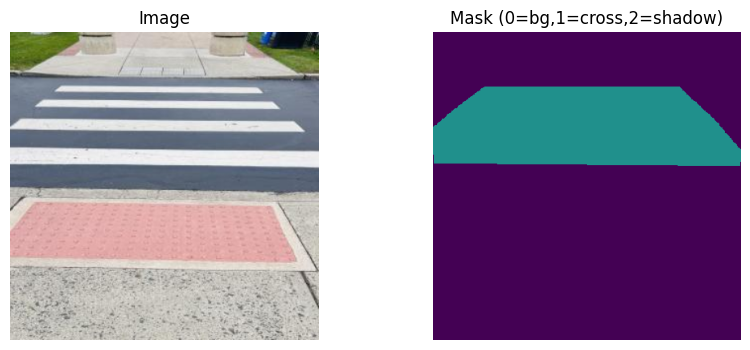

In [6]:
def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img = img_tensor * std + mean
    return img.clamp(0,1)

def show_image_and_mask(img_tensor, mask_tensor):
    img = denormalize(img_tensor).permute(1,2,0).cpu().numpy()
    mask = mask_tensor.cpu().numpy()

    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1); plt.imshow(img);  plt.title("Image"); plt.axis("off")
    plt.subplot(1,2,2); plt.imshow(mask, vmin=0, vmax=2); plt.title("Mask (0=bg,1=cross,2=shadow)"); plt.axis("off")
    plt.show()
    
images, masks = next(iter(train_loader))
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Unique mask values:", masks.unique())
show_image_and_mask(images[7], masks[7])

# Loading DeepLabv3+ and replacing last layer

In [7]:
model = torchvision.models.segmentation.deeplabv3_resnet50(weights="DEFAULT")

model.classifier[-1] = nn.Conv2d(in_channels=256, out_channels=3, kernel_size=1)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

# IoU metric for segmentation

In [8]:
def compute_mean_iou(preds, targets, num_classes=3):
    ious = []
    preds = preds.cpu()
    targets = targets.cpu()

    for cls in range(num_classes):
        pred_cls = (preds == cls)
        target_cls = (targets == cls)

        intersection = (pred_cls & target_cls).sum().item()
        union = (pred_cls | target_cls).sum().item()

        if union == 0:
            continue  
        ious.append(intersection / union)

    if len(ious) == 0:
        return 0.0
    return sum(ious) / len(ious)


# Baseline Evaluation (Without Any Training as Per Requirement)

In [9]:
def evaluate_baseline(model, loader, split_name=""):
    model.eval()
    total_loss = 0.0
    total_iou  = 0.0
    num_batches = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks  = masks.to(device)

            outputs = model(images)["out"]   
            loss = criterion(outputs, masks)

            preds = outputs.argmax(dim=1)    

            batch_iou = compute_mean_iou(preds, masks, num_classes=3)

            total_loss += loss.item()
            total_iou  += batch_iou
            num_batches += 1

    avg_loss = total_loss / num_batches
    avg_iou  = total_iou / num_batches

    print(f"{split_name} - Avg loss: {avg_loss:.4f}, Mean IoU: {avg_iou:.4f}")
    return avg_loss, avg_iou

train_loss, train_iou = evaluate_baseline(model, train_loader, split_name="Train (baseline, no training)")
val_loss,   val_iou   = evaluate_baseline(model, val_loader,   split_name="Val   (baseline, no training)")

Train (baseline, no training) - Avg loss: 1.4113, Mean IoU: 0.0351
Val   (baseline, no training) - Avg loss: 1.3801, Mean IoU: 0.0528


# Visualizing the 1st sample of each minibatch of size 8 and its prediction

In [10]:
def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img = img_tensor * std + mean
    return img.clamp(0,1)

In [11]:
def visualize_batch_predictions(model, loader, num_batches=3):
    model.eval()
    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(loader):
            if batch_idx >= num_batches:
                break

            images = images.to(device)

            outputs = model(images)["out"]
            preds = outputs.argmax(dim=1)  

            img = images[0].cpu()
            gt_mask = masks[0].cpu()        
            pred_mask = preds[0].cpu()

            img_vis = denormalize(img).permute(1,2,0).numpy()

            plt.figure(figsize=(12,4))
            plt.subplot(1,3,1); plt.imshow(img_vis);     plt.title(f"Batch {batch_idx} - Image"); plt.axis("off")
            plt.subplot(1,3,2); plt.imshow(gt_mask, vmin=0, vmax=2);   plt.title("GT Mask"); plt.axis("off")
            plt.subplot(1,3,3); plt.imshow(pred_mask, vmin=0, vmax=2); plt.title("Pred Mask (baseline)"); plt.axis("off")
            plt.show()

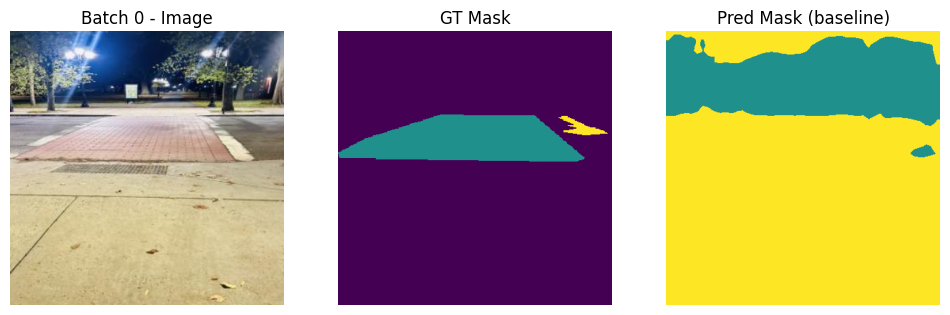

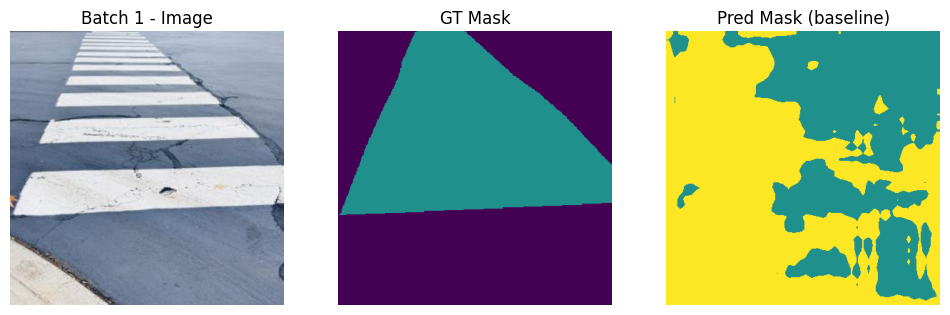

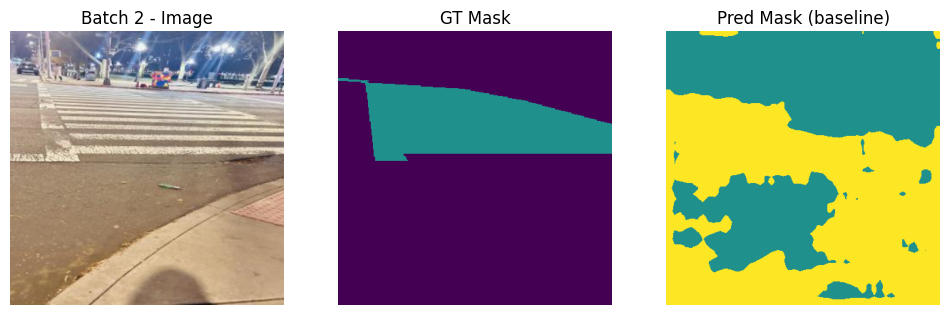

In [12]:
visualize_batch_predictions(model, train_loader, num_batches=3)

# Continuation for Final Parts of the Project

# Performing Hyperprameter Tuning via Random Search. 

In [5]:
num_classes = 3  

def build_model():
    model = torchvision.models.segmentation.deeplabv3_resnet50(weights="DEFAULT")
    model.classifier[-1] = nn.Conv2d(256, num_classes, kernel_size=1)
    return model.to(device)

In [14]:
ce_loss = nn.CrossEntropyLoss()

def dice_loss(outputs, targets, eps=1e-6):

    num_classes = outputs.shape[1]
    targets_one_hot = F.one_hot(targets, num_classes=num_classes)  
    targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float() 
    probs = F.softmax(outputs, dim=1)

    dims = (0, 2, 3)
    intersection = torch.sum(probs * targets_one_hot, dims)
    cardinality  = torch.sum(probs + targets_one_hot, dims)

    dice = (2.0 * intersection + eps) / (cardinality + eps)
    dice_fg = dice[1:] 
    loss = 1.0 - dice_fg.mean()
    return loss

def combined_loss(outputs, targets, alpha=0.5):
    l_ce   = ce_loss(outputs, targets)
    l_dice = dice_loss(outputs, targets)
    return alpha * l_ce + (1 - alpha) * l_dice

criterion = combined_loss

In [15]:
def train_one_epoch(model, loader, optimizer, criterion, epoch, max_grad_norm=None):
    model.train()
    running_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks  = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)["out"]
        loss = criterion(outputs, masks)
        loss.backward()

        if max_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)

        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(loader)
    print(f"Epoch {epoch}: train loss = {avg_loss:.4f}")
    return avg_loss

In [16]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_iou  = 0.0
    num_batches = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks  = masks.to(device)

            outputs = model(images)["out"]
            loss = criterion(outputs, masks)
            preds = outputs.argmax(dim=1)

            batch_iou = compute_mean_iou(preds, masks, num_classes=3)

            total_loss += loss.item()
            total_iou  += batch_iou
            num_batches += 1

    avg_loss = total_loss / num_batches
    avg_iou  = total_iou / num_batches
    return avg_loss, avg_iou

In [17]:
def sample_random_config():
    log_lr = random.uniform(math.log10(3e-5), math.log10(3e-3))
    lr = 10 ** log_lr

    weight_decay = random.choice([0.0, 1e-5, 1e-4])

    epochs = 5

    return {
        "lr": lr,
        "weight_decay": weight_decay,
        "epochs": epochs
    }

In [18]:
num_trials = 6  

best_config = None
best_val_iou = -1.0
all_results = []

for trial in range(1, num_trials + 1):
    cfg = sample_random_config()
    print(f"\n================ Random trial {trial}/{num_trials} ================")
    print("Config:", cfg)

    # fresh model for each trial
    model = build_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"]
    )

    best_iou_this_cfg = -1.0
    best_epoch_this_cfg = 0

    for epoch in range(1, cfg["epochs"] + 1):
        train_one_epoch(model, train_loader, optimizer, criterion, epoch)
        val_loss, val_iou = evaluate(model, val_loader, criterion)
        print(f"   Epoch {epoch}: val loss = {val_loss:.4f}, val IoU = {val_iou:.4f}")

        if val_iou > best_iou_this_cfg:
            best_iou_this_cfg = val_iou
            best_epoch_this_cfg = epoch

    all_results.append({
        "config": cfg,
        "best_val_iou": best_iou_this_cfg,
        "best_epoch": best_epoch_this_cfg
    })

    # update global best
    if best_iou_this_cfg > best_val_iou:
        best_val_iou = best_iou_this_cfg
        best_config = cfg

print("\n================ Summary of random search ================")
for res in all_results:
    print(f"Config {res['config']} -> best val IoU {res['best_val_iou']:.4f} at epoch {res['best_epoch']}")

print("\nBest overall config:", best_config, "with val IoU =", best_val_iou)


================ Random trial 1/6 ================
Config: {'lr': 0.00019776332756806536, 'weight_decay': 0.0001, 'epochs': 5}
Epoch 1: train loss = 0.5973
   Epoch 1: val loss = 0.5356, val IoU = 0.5329
Epoch 2: train loss = 0.4175
   Epoch 2: val loss = 0.4221, val IoU = 0.8036
Epoch 3: train loss = 0.3496
   Epoch 3: val loss = 0.4422, val IoU = 0.5691
Epoch 4: train loss = 0.3198
   Epoch 4: val loss = 0.9658, val IoU = 0.4990
Epoch 5: train loss = 0.3274
   Epoch 5: val loss = 0.3566, val IoU = 0.6377

================ Random trial 2/6 ================
Config: {'lr': 0.0002709347042771855, 'weight_decay': 0.0001, 'epochs': 5}
Epoch 1: train loss = 0.6213
   Epoch 1: val loss = 0.5677, val IoU = 0.5306
Epoch 2: train loss = 0.4203
   Epoch 2: val loss = 0.4175, val IoU = 0.7071
Epoch 3: train loss = 0.3575
   Epoch 3: val loss = 1.0166, val IoU = 0.4466
Epoch 4: train loss = 0.3429
   Epoch 4: val loss = 0.3475, val IoU = 0.8496
Epoch 5: train loss = 0.3052
   Epoch 5: val loss = 

# Finetuning the Network and Saving the Best Model (based on mIoU)

In [22]:
print("Using best config for full fine-tuning:", best_config)

model = build_model()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=best_config["lr"],
    weight_decay=best_config["weight_decay"]
)

num_epochs = 20

best_val_iou = -1.0
best_epoch = -1
best_state = None

train_history = []
val_loss_history = []
val_iou_history = []

num_epochs = 20

for epoch in range(1, num_epochs + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, epoch)
    val_loss, val_iou = evaluate(model, val_loader, criterion)

    train_history.append(train_loss)
    val_loss_history.append(val_loss)
    val_iou_history.append(val_iou)

    print(f"FULL Epoch {epoch}: val loss = {val_loss:.4f}, val IoU = {val_iou:.4f}")

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

Using best config for full fine-tuning: {'lr': 0.0002709347042771855, 'weight_decay': 0.0001, 'epochs': 5}
Epoch 1: train loss = 0.5924
FULL Epoch 1: val loss = 0.5209, val IoU = 0.5510
Epoch 2: train loss = 0.4147
FULL Epoch 2: val loss = 0.4492, val IoU = 0.6719
Epoch 3: train loss = 0.3597
FULL Epoch 3: val loss = 0.4052, val IoU = 0.6910
Epoch 4: train loss = 0.3284
FULL Epoch 4: val loss = 0.4077, val IoU = 0.6834
Epoch 5: train loss = 0.3175
FULL Epoch 5: val loss = 0.4106, val IoU = 0.6948
Epoch 6: train loss = 0.2750
FULL Epoch 6: val loss = 0.3962, val IoU = 0.8015
Epoch 7: train loss = 0.3207
FULL Epoch 7: val loss = 0.4120, val IoU = 0.6834
Epoch 8: train loss = 0.2903
FULL Epoch 8: val loss = 0.3878, val IoU = 0.5920
Epoch 9: train loss = 0.2449
FULL Epoch 9: val loss = 0.4094, val IoU = 0.6992
Epoch 10: train loss = 0.2784
FULL Epoch 10: val loss = 0.3895, val IoU = 0.7059
Epoch 11: train loss = 0.2577
FULL Epoch 11: val loss = 0.3961, val IoU = 0.6898
Epoch 12: train loss

In [25]:
print(f"Best epoch: {best_epoch} with val mIoU = {best_val_iou:.4f}")
model.load_state_dict(best_state)

Best epoch: 20 with val mIoU = 0.8289


<All keys matched successfully>

In [26]:
torch.save(best_state, "best_deeplab_crosswalk_shadow.pth")

# Graph Plots to Visualize Our Training

## Loss Curves

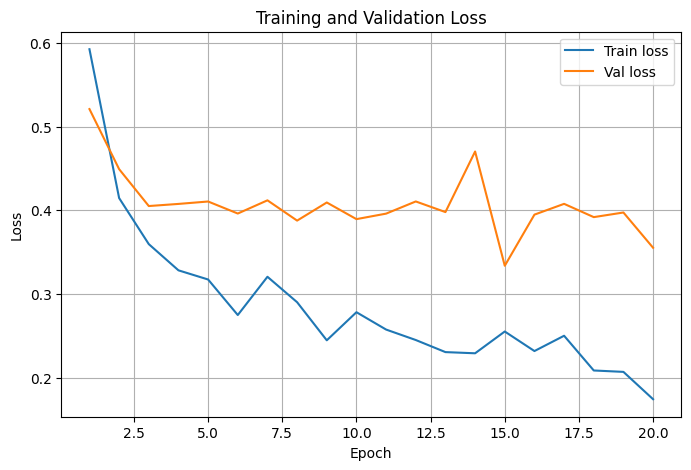

In [23]:
epochs = range(1, len(train_history) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs, train_history, label="Train loss")
plt.plot(epochs, val_loss_history, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## mIoU Graph

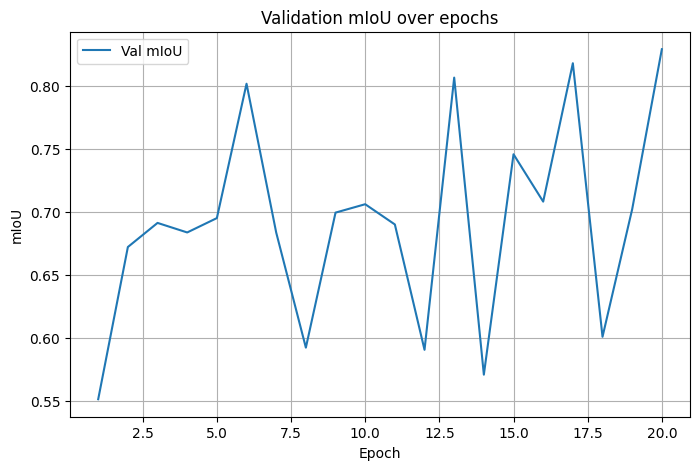

In [24]:
plt.figure(figsize=(8,5))
plt.plot(epochs, val_iou_history, label="Val mIoU")
plt.xlabel("Epoch")
plt.ylabel("mIoU")
plt.title("Validation mIoU over epochs")
plt.legend()
plt.grid(True)
plt.show()

# Using Gradio to take Images as Input and Provide the Image Segmentation as Output

## Rebuilding the Model for Inference

In [6]:
model = build_model()
state_dict = torch.load("best_deeplab_crosswalk_shadow.pth", map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

C:\Users\miste\AppData\Local\Temp\ipykernel_15876\1224963216.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load("best_deeplab_crosswalk_shadow.pth",

DeepLabV3(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Se

## Defining the Same Preprocessing as Training

In [7]:
TARGET_SIZE = (384, 384)  

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def preprocess_image(pil_img: Image.Image):

    pil_img = pil_img.convert("RGB")

    # Resize
    pil_resized = pil_img.resize(TARGET_SIZE, Image.BILINEAR)

    tensor = TF.to_tensor(pil_resized)
    tensor = TF.normalize(tensor, IMAGENET_MEAN, IMAGENET_STD)

    return pil_img, tensor.unsqueeze(0)

## Post-processing: Colorizing and Overlaying the Mask

In [8]:
def mask_to_color(mask_np):

    h, w = mask_np.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)

    color_mask[mask_np == 1] = np.array([0, 255, 0], dtype=np.uint8)
    color_mask[mask_np == 2] = np.array([0, 0, 255], dtype=np.uint8)

    return color_mask


def overlay_segmentation(original_pil, mask_np, alpha=0.5):

    orig_w, orig_h = original_pil.size

    mask_img = Image.fromarray(mask_np.astype(np.uint8), mode="L")
    mask_img = mask_img.resize((orig_w, orig_h), Image.NEAREST)
    mask_resized = np.array(mask_img)

    color_mask = mask_to_color(mask_resized)

    original_np = np.array(original_pil).astype(np.float32)

    overlay = original_np.copy()
    non_bg = mask_resized > 0

    overlay[non_bg] = (1 - alpha) * overlay[non_bg] + alpha * color_mask[non_bg]
    overlay = overlay.astype(np.uint8)

    return overlay

# Defining the Gradio Prediction Function

In [9]:
def predict_segmentation(pil_img):
    
    original_pil, tensor_batch = preprocess_image(pil_img)
    tensor_batch = tensor_batch.to(device)

    with torch.no_grad():
        outputs = model(tensor_batch)["out"] 
        preds = outputs.argmax(dim=1)      
        mask_np = preds.squeeze(0).cpu().numpy().astype(np.uint8)

    overlay = overlay_segmentation(original_pil, mask_np, alpha=0.5)
    return overlay

# Building and launching the Gradio Interface

In [10]:
demo = gr.Interface(
    fn=predict_segmentation,
    inputs=gr.Image(type="pil", label="Input image"),
    outputs=gr.Image(type="numpy", label="Segmented overlay"),
    title="Crosswalk & Shadow Semantic Segmentation",
    description="Upload any road/crosswalk image and the model will highlight crosswalk stripes and shadows."
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


C:\Users\miste\AppData\Local\Temp\ipykernel_15876\2319913280.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_img = Image.fromarray(mask_np.astype(np.uint8), mode="L")
Traceback (most recent call last):
  File "C:\Users\miste\miniconda3\envs\crosswalk_seg\lib\site-packages\gradio\queueing.py", line 763, in process_events
    response = await route_utils.call_process_api(
  File "C:\Users\miste\miniconda3\envs\crosswalk_seg\lib\site-packages\gradio\route_utils.py", line 354, in call_process_api
    output = await app.get_blocks().process_api(
  File "C:\Users\miste\miniconda3\envs\crosswalk_seg\lib\site-packages\gradio\blocks.py", line 2106, in process_api
    result = await self.call_function(
  File "C:\Users\miste\miniconda3\envs\crosswalk_seg\lib\site-packages\gradio\blocks.py", line 1588, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
  File "C:\Users\miste\miniconda3\envs\crosswalk_seg